<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/lab-011-cnn-tc.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 011 <br>
**Reading:** Lecture Notes, Chapter 2 (*Fundamentals of Deep Learning*), Section *Deep Learning in the Classical 2D Ising Model*; Section *Understanding Deep Learning through the Chinese Room Thought Experiment*
<hr/>

# Lab 011 — Finding $T_c$ of the 2D Ising model from the confidence of a CNN

This notebook reproduces the experiment of Lecture 4 (Lecture Notes, Chapter 2):

1. Take Monte Carlo spin configurations of an $L\times L$ Ising model on a grid of temperatures (from Lab 010, or generated here).
2. Label **only** the configurations far from the transition: $T<1.5$ as *ordered* ($y=0$) and $T>3.0$ as *disordered* ($y=1$). Everything in between is never shown to the network during training.
3. Train a small **CNN** to tell the two classes apart.
4. Ask the trained network about **all** temperatures. Where is it least confident? That temperature, $\bar T_c$, is our estimate of $T_c$.
5. Repeat for several lattice sizes (**finite-size effects**).
6. **Open the Chinese room** (Lecture 4): what did the network actually learn?

The exact answer, for comparison: $T_c = 2/\ln(1+\sqrt2)$ (Onsager 1944, $J=k_B=1$).

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `scipy`, `matplotlib`, `torch`) are pre-installed in Colab; no `pip install` required.
> 4. The notebook looks for the dataset `data/ising_Nx{L}_Ny{L}.npz` made by Lab 010. If it is not there, it generates it (this takes from seconds to about a minute, depending on $L$).
>    In Colab you can upload the file from Lab 010 into a folder `data/`, or just let the notebook generate it.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
import torch
import torch.nn as nn

torch.manual_seed(0)                    # fixes the random initial parameters
rng = np.random.default_rng(0)          # NumPy random generator (data generation, train/validation split)

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
cmap_T = LinearSegmentedColormap.from_list("T", [UJNavy, "#D9DCE1", DSOrange])   # below T_c -> above T_c
cmap_w = LinearSegmentedColormap.from_list("w", [UJNavy, "white", DSOrange])     # for weights (sign)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))
print("PyTorch", torch.__version__, "  NumPy", np.__version__, f"   exact T_c = {TC:.6f}")

PyTorch 2.9.0+cpu   NumPy 2.1.3    exact T_c = 2.269185


<hr/>
## 1. The data

We need configurations $\boldsymbol s\in\{-1,+1\}^{L\times L}$ sampled from $p(\boldsymbol s)\propto e^{-H(\boldsymbol s)/T}$ on a grid of temperatures.
The cell below contains a compact copy of the checkerboard Metropolis sampler of Lab 010 (see Lab 010 for its derivation and its tests).
It produces the same file format, so the two notebooks can share data: `configs` with shape `(temperatures, samples, L, L)` and the temperature grid `T`.

In [2]:
def metropolis_sweep(s, beta, masks, rng):
    # One checkerboard Metropolis sweep (in place) of a batch of lattices s: (..., Ny, Nx), periodic boundaries.
    for mask in masks:
        nn_sum = (np.roll(s, 1, -1) + np.roll(s, -1, -1) + np.roll(s, 1, -2) + np.roll(s, -1, -2))
        accept = rng.random(s.shape, dtype=np.float32) < np.exp(-beta * 2.0 * s * nn_sum)
        s[...] = np.where(mask & accept, -s, s)

def generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng):
    # Cold start, burn-in, then n_samples stored configurations per chain; random global spin flip at the end.
    y, x = np.indices((Ny, Nx)); black = (x + y) % 2 == 0
    beta = (1.0 / temperatures.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temperatures), Ny, Nx), np.float32)
    for _ in range(n_equil):
        metropolis_sweep(s, beta, (black, ~black), rng)
    stored = np.empty((n_samples, n_chains, len(temperatures), Ny, Nx), np.int8)
    for k in range(n_samples):
        for _ in range(n_between):
            metropolis_sweep(s, beta, (black, ~black), rng)
        stored[k] = s
    configs = stored.transpose(2, 0, 1, 3, 4).reshape(len(temperatures), n_samples * n_chains, Ny, Nx)
    flip = rng.choice(np.array([-1, 1], np.int8), size=configs.shape[:2])
    return configs * flip[:, :, None, None]

def load_or_generate(L, rng, samples_per_T=200):
    path = f"data/ising_Nx{L}_Ny{L}.npz"
    if os.path.exists(path):
        d = np.load(path)
        print(f"loaded {path}: configs {d['configs'].shape}")
        return d["configs"], d["T"]
    temperatures = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
    n_chains = 20 if L <= 20 else 10                       # fewer, longer chains for large lattices (same 200 samples per T)
    t0 = time.time()
    configs = generate_dataset(L, L, temperatures, n_chains=n_chains, n_samples=samples_per_T // n_chains,
                               n_equil=1000 + 2 * L * L // 4, n_between=20, rng=rng)
    os.makedirs("data", exist_ok=True)
    np.savez_compressed(path, configs=configs, T=temperatures, Nx=L, Ny=L)
    print(f"generated {path}: configs {configs.shape} in {time.time() - t0:.1f} s")
    return configs, temperatures

L = 20
configs, temperatures = load_or_generate(L, rng)

loaded data/ising_Nx20_Ny20.npz: configs (51, 200, 20, 20)


<hr/>
## 2. The task: a classifier trained only far from $T_c$

Each configuration gets a label from its temperature:
$$
y = \begin{cases} 0 \ (\text{ordered}) & T < T_{\min}=1.5\\ 1 \ (\text{disordered}) & T>T_{\max}=3.0 \\ \text{not used for training} & T_{\min}\le T\le T_{\max}\end{cases}
$$
The network outputs two numbers (logits) $z_0, z_1$, turned into probabilities by the **softmax**
$$
p_k(\boldsymbol s) = \frac{e^{z_k}}{e^{z_0}+e^{z_1}}, \qquad p_0+p_1 = 1,
$$
and is trained by minimising the **categorical cross-entropy** $\mathcal L = -\frac1n\sum_{a}\ln p_{y_a}(\boldsymbol s_a)$ (Lecture 4).

**Confidence.** For any configuration the prediction is the class with the larger probability, and the confidence is that probability:
$$
\mathrm{conf}(\boldsymbol s) = \max\left(p_0(\boldsymbol s),\,p_1(\boldsymbol s)\right)\in\left[\tfrac12, 1\right].
$$
The network is confident on configurations that look like its training data. Close to $T_c$ the configurations are neither clearly ordered nor clearly disordered,
so we expect $\mathrm{conf}\to\frac12$ there. We define
$$
\bar T_c = \arg\min_T \ \big\langle \mathrm{conf}\big\rangle_T ,
$$
the temperature of lowest average confidence. A closely related estimate is the temperature where the average $\langle p_1\rangle_T$ crosses $\frac12$.

In [3]:
T_MIN, T_MAX = 1.5, 3.0

def make_training_set(configs, temperatures, rng, val_fraction=0.2):
    low, high = temperatures < T_MIN, temperatures > T_MAX
    X = np.concatenate([configs[low].reshape(-1, *configs.shape[2:]), configs[high].reshape(-1, *configs.shape[2:])])
    y = np.concatenate([np.zeros(configs[low].shape[0] * configs.shape[1]), np.ones(configs[high].shape[0] * configs.shape[1])])
    perm = rng.permutation(len(y))
    X, y = X[perm], y[perm]
    n_val = int(val_fraction * len(y))
    to_t = lambda a: torch.tensor(a, dtype=torch.float32).unsqueeze(1)   # (n, 1, L, L): one input channel
    return (to_t(X[n_val:]), torch.tensor(y[n_val:], dtype=torch.long),
            to_t(X[:n_val]), torch.tensor(y[:n_val], dtype=torch.long))

X_tr, y_tr, X_val, y_val = make_training_set(configs, temperatures, rng)
print(f"training: {len(y_tr)} configurations, validation: {len(y_val)};  fraction of label 1 in training = {y_tr.float().mean():.3f}")
print(f"temperatures used for label 0: {temperatures[temperatures < T_MIN]}")
print(f"temperatures used for label 1: {temperatures[temperatures > T_MAX]}")

training: 3200 configurations, validation: 800;  fraction of label 1 in training = 0.496
temperatures used for label 0: [1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45]
temperatures used for label 1: [3.05 3.1  3.15 3.2  3.25 3.3  3.35 3.4  3.45 3.5 ]


<hr/>
## 3. The network

As in the Lecture Notes: two convolutional layers with $32$ kernels of size $3\times3$, each followed by ReLU and $2\times2$ max-pooling, then a dense layer of $64$
ReLU nodes and an output layer of $2$ nodes (softmax inside the loss).

One physics-motivated detail: we use **circular padding** (`padding_mode="circular"`). Our lattice is a torus, so the neighbour of the last column is the first column;
circular padding makes the convolution see exactly the same neighbourhoods as the Hamiltonian.

In [4]:
class IsingCNN(nn.Module):
    def __init__(self, L, channels=32, hidden=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(channels, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2))
        side = L // 4                                          # two 2x2 poolings
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(channels * side * side, hidden), nn.ReLU(),
                                        nn.Linear(hidden, 2))
    def forward(self, x):
        return self.classifier(self.features(x))               # logits z_0, z_1

model = IsingCNN(L)
W0 = model.features[0].weight.detach().clone()                 # first-layer filters before training (used in Section 7.3)
print(model)
print("number of parameters:", sum(p.numel() for p in model.parameters()))

IsingCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), padding_mode=circular)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), padding_mode=circular)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=800, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
number of parameters: 60962


<hr/>
## 4. Training

In [5]:
def train(model, X_tr, y_tr, X_val, y_val, epochs=5, batch_size=64, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()                            # softmax + categorical cross-entropy
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(y_tr))
        for i in range(0, len(y_tr), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out_tr, out_val = model(X_tr), model(X_val)
            rec = (loss_fn(out_tr, y_tr).item(), (out_tr.argmax(1) == y_tr).float().mean().item(),
                   loss_fn(out_val, y_val).item(), (out_val.argmax(1) == y_val).float().mean().item())
        history.append(rec)
        if verbose:
            print(f"epoch {epoch + 1:2d}: train loss {rec[0]:.2e} acc {rec[1]:.4f} | validation loss {rec[2]:.2e} acc {rec[3]:.4f}")
    return np.array(history)

t0 = time.time()
history = train(model, X_tr, y_tr, X_val, y_val)
print(f"training time: {time.time() - t0:.1f} s")

epoch  1: train loss 5.89e-06 acc 1.0000 | validation loss 5.81e-06 acc 1.0000


epoch  2: train loss 3.47e-06 acc 1.0000 | validation loss 3.39e-06 acc 1.0000


epoch  3: train loss 2.88e-06 acc 1.0000 | validation loss 2.86e-06 acc 1.0000


epoch  4: train loss 2.51e-06 acc 1.0000 | validation loss 2.52e-06 acc 1.0000


epoch  5: train loss 2.23e-06 acc 1.0000 | validation loss 2.26e-06 acc 1.0000
training time: 4.3 s


The two classes are easy to separate (at $T<1.5$ almost all spins are aligned, at $T>3$ they are not), so the training and validation accuracies come out
close to $1$. That is not the interesting part. The interesting part is what the network says about temperatures it has **never seen**.
<hr/>
## 5. Asking the network about all temperatures

In [6]:
def predict(model, configs):
    # Softmax probabilities p_1 (disordered) for all configurations: array (temperatures, samples).
    model.eval()
    X = torch.tensor(configs.reshape(-1, 1, *configs.shape[2:]), dtype=torch.float32)
    with torch.no_grad():
        p = torch.cat([torch.softmax(model(X[i:i + 2048]), dim=1)[:, 1] for i in range(0, len(X), 2048)])
    return p.numpy().reshape(configs.shape[:2])

def estimate_Tc(temperatures, p1):
    conf = np.maximum(p1, 1 - p1)
    conf_mean, p1_mean = conf.mean(1), p1.mean(1)
    T_conf = temperatures[np.argmin(conf_mean)]                       # lowest average confidence
    i = np.argmax(p1_mean >= 0.5)                                     # first temperature where <p_1> >= 1/2
    T_cross = temperatures[i - 1] + (0.5 - p1_mean[i - 1]) * (temperatures[i] - temperatures[i - 1]) / (p1_mean[i] - p1_mean[i - 1])
    return conf_mean, p1_mean, T_conf, T_cross

p1 = predict(model, configs)
conf_mean, p1_mean, T_conf, T_cross = estimate_Tc(temperatures, p1)
print(f"L = {L}:  T_c from minimum of confidence = {T_conf:.2f}   |  T_c from <p_1> = 1/2 crossing = {T_cross:.3f}   |  exact T_c = {TC:.4f}")

L = 20:  T_c from minimum of confidence = 2.20   |  T_c from <p_1> = 1/2 crossing = 2.247   |  exact T_c = 2.2692


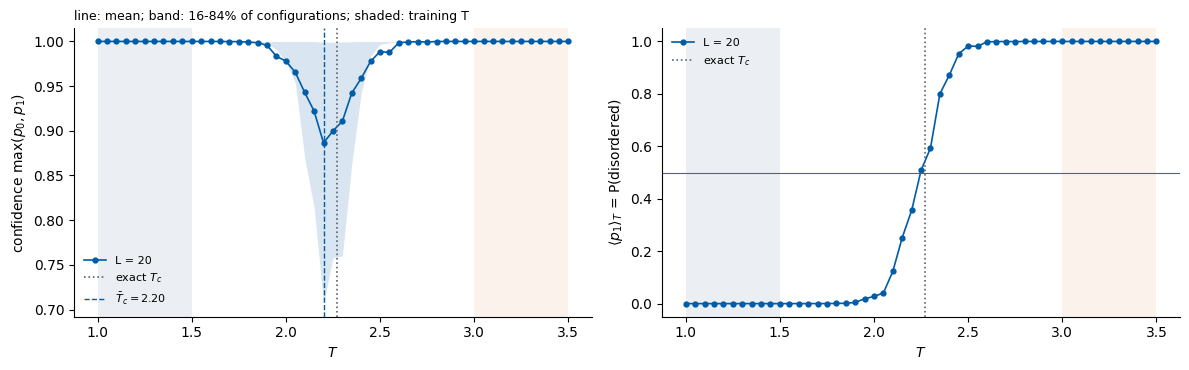

In [7]:
def plot_confidence(ax_conf, ax_p, temperatures, p1, label, colour, marker="o", band=True):
    conf = np.maximum(p1, 1 - p1)
    ax_conf.plot(temperatures, conf.mean(1), marker + "-", ms=3.5, lw=1.2, color=colour, label=label)
    if band:                                                   # spread over configurations: 16th to 84th percentile
        ax_conf.fill_between(temperatures, *np.percentile(conf, [16, 84], axis=1), color=colour, alpha=0.15, lw=0)
    ax_p.plot(temperatures, p1.mean(1), marker + "-", ms=3.5, lw=1.2, color=colour, label=label)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
plot_confidence(ax1, ax2, temperatures, p1, f"L = {L}", UJBlue)
for ax in (ax1, ax2):
    ax.axvspan(temperatures.min(), T_MIN, color=UJNavy, alpha=0.08, lw=0)
    ax.axvspan(T_MAX, temperatures.max(), color=DSOrange, alpha=0.08, lw=0)
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2, label=r"exact $T_c$")
    ax.set_xlabel("$T$")
ax1.axvline(T_conf, color=UJBlue, ls="--", lw=1, label=rf"$\bar T_c = {T_conf:.2f}$")
ax2.axhline(0.5, color=UJGray, lw=0.8)
ax1.set_ylabel(r"confidence $\max(p_0,p_1)$"); ax2.set_ylabel(r"$\langle p_1\rangle_T$ = P(disordered)")
ax1.legend(frameon=False, fontsize=8, loc="lower left"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
ax1.set_title("line: mean; band: 16-84% of configurations; shaded: training T", loc="left", fontsize=9)
fig.tight_layout(); plt.show()

**Reading the plot.**
* In the shaded regions the network is (as trained) nearly certain.
* Between them it was never told anything, yet its output switches from "ordered" to "disordered" in a narrow window, and the confidence has a sharp
  minimum there. Compare the printed $\bar T_c$ with the exact $T_c$.
* The band shows the spread over individual configurations: right at the minimum some configurations are classified confidently as ordered and others
  as disordered. The *average* confidence is low because the configurations at that temperature are a mixture of both.
<hr/>
## 6. Finite-size effects

The network sees an $L\times L$ lattice, which has no sharp phase transition (Lab 010, Section 8). We repeat the whole experiment — data, training,
prediction — for $L=10, 20, 40$ with the same network architecture and the same training temperatures. Each training is repeated with $3$ random seeds,
because a single training run is itself a random experiment.

loaded data/ising_Nx10_Ny10.npz: configs (51, 200, 10, 10)


loaded data/ising_Nx20_Ny20.npz: configs (51, 200, 20, 20)


loaded data/ising_Nx40_Ny40.npz: configs (51, 200, 40, 40)


3 trainings for each of 3 lattice sizes done in 38 s


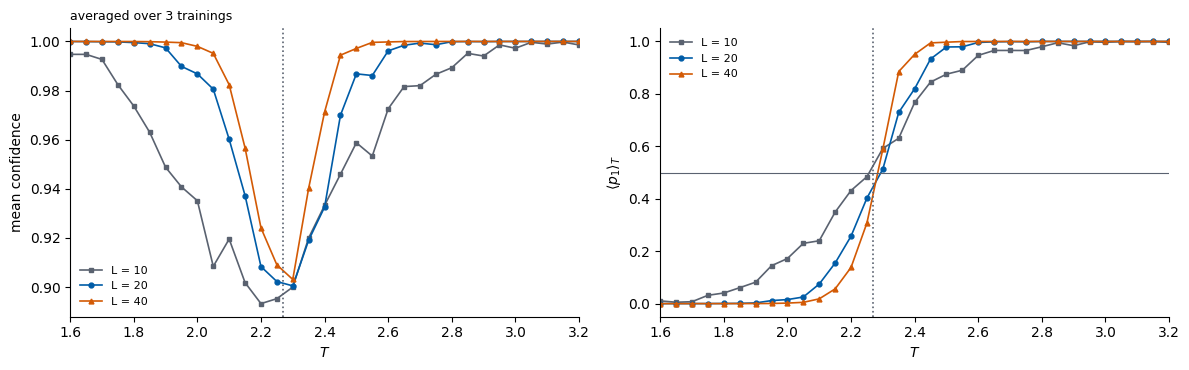

  L   T_c (min confidence), per seed     T_c (<p_1> = 1/2), per seed       mean +- std of the crossing   exact
 10   2.20  2.20  2.25                 2.207  2.245  2.290              2.247 +- 0.041               2.2692
 20   2.20  2.30  2.25                 2.240  2.310  2.304              2.285 +- 0.039               2.2692
 40   2.25  2.25  2.30                 2.282  2.249  2.319              2.283 +- 0.035               2.2692


In [8]:
results = {}                                                 # results[L] = list over training seeds of (T, p_1, T_conf, T_cross)
seeds = (0, 1, 2)
t0 = time.time()
for L_fs in (10, 20, 40):
    cfg, Ts = load_or_generate(L_fs, rng)
    results[L_fs] = []
    for seed in seeds:
        torch.manual_seed(seed)                                  # different random initialisation and batches
        Xa, ya, Xb, yb = make_training_set(cfg, Ts, np.random.default_rng(seed))
        m = IsingCNN(L_fs)
        train(m, Xa, ya, Xb, yb, epochs=3, verbose=False)        # the task is easy: 3 epochs are enough (see Section 4)
        pp = predict(m, cfg)
        _, _, Tc1, Tc2 = estimate_Tc(Ts, pp)
        results[L_fs].append((Ts, pp, Tc1, Tc2))
print(f"{len(seeds)} trainings for each of 3 lattice sizes done in {time.time() - t0:.0f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
styles = {10: (UJGray, "s"), 20: (UJBlue, "o"), 40: (DSOrange, "^")}
for L_fs in sorted(results):
    Ts = results[L_fs][0][0]
    pp = np.concatenate([r[1] for r in results[L_fs]], axis=1)   # pool the seeds
    plot_confidence(ax1, ax2, Ts, pp, f"L = {L_fs}", *styles[L_fs], band=False)
for ax in (ax1, ax2):
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_xlim(1.6, 3.2)
ax2.axhline(0.5, color=UJGray, lw=0.8)
ax1.set_ylabel("mean confidence"); ax2.set_ylabel(r"$\langle p_1\rangle_T$")
ax1.set_title(f"averaged over {len(seeds)} trainings", loc="left", fontsize=9)
ax1.legend(frameon=False, fontsize=8, loc="lower left"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

print("  L   T_c (min confidence), per seed     T_c (<p_1> = 1/2), per seed       mean +- std of the crossing   exact")
for L_fs in sorted(results):
    t1 = np.array([r[2] for r in results[L_fs]]); t2 = np.array([r[3] for r in results[L_fs]])
    print(f"{L_fs:3d}   {'  '.join(f'{v:.2f}' for v in t1):30s}   {'  '.join(f'{v:.3f}' for v in t2):30s}   "
          f"{t2.mean():.3f} +- {t2.std(ddof=1):.3f}               {TC:.4f}")

**What to notice.**
* The switch from "ordered" to "disordered" becomes **sharper** as $L$ grows: the transition region of a finite lattice shrinks (Lab 010).
* The estimates depend on $L$, on the temperature grid (spacing $0.05$) and on the random training run — compare the per-seed values in the table:
  the seed-to-seed spread is not small compared with the distance to $T_c$. A single number such as "$\bar T_c$ for $L=50$" is a
  *pseudo-critical* temperature; extracting $T_c$ itself needs several $L$ and an extrapolation $L\to\infty$.
<hr/>
## 7. Opening the Chinese room: what the network learned

The network located the transition, but it did not *tell* us anything — no order parameter, no mechanism (Lecture 4, *The Chinese Room*). Can we look inside?

### 7.1 Output vs magnetisation
For every configuration we compute $|m| = \frac1N\left|\sum_i s_i\right|$ and plot it against the network output $p_1$. If the network had learned "$p_1$ is a
function of $|m|$", all points would collapse onto one curve, whatever their temperature.

Spearman rank correlation between |m| and p_1 over all 10200 configurations: -0.914


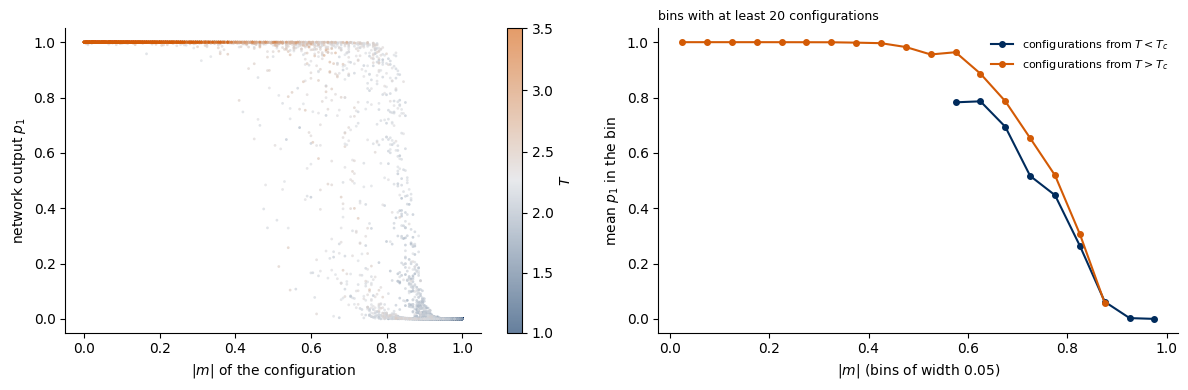

In [9]:
L = 20
absm = np.abs(configs.reshape(*configs.shape[:2], -1).mean(-1).astype(np.float64))     # (temperatures, samples)
TT = np.repeat(temperatures[:, None], configs.shape[1], axis=1)

rho, _ = spearmanr(absm.ravel(), p1.ravel())
print(f"Spearman rank correlation between |m| and p_1 over all {absm.size} configurations: {rho:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sc = ax1.scatter(absm.ravel(), p1.ravel(), c=TT.ravel(), cmap=cmap_T, norm=TwoSlopeNorm(TC, temperatures.min(), temperatures.max()),
                 s=4, alpha=0.6, lw=0)
plt.colorbar(sc, ax=ax1, label="$T$")
ax1.set_xlabel(r"$|m|$ of the configuration"); ax1.set_ylabel(r"network output $p_1$")

# binned mean of p_1 at fixed |m|, separately for configurations from below and above T_c
bins = np.linspace(0, 1, 21)
centres = 0.5 * (bins[1:] + bins[:-1])
for sel, col, lab in ((TT < TC, UJNavy, r"configurations from $T<T_c$"), (TT > TC, DSOrange, r"configurations from $T>T_c$")):
    idx = np.digitize(absm[sel], bins) - 1
    mean_p = np.array([p1[sel][idx == b].mean() if np.sum(idx == b) >= 20 else np.nan for b in range(len(centres))])
    ax2.plot(centres, mean_p, "o-", color=col, ms=4, label=lab)
ax2.set_xlabel(r"$|m|$ (bins of width 0.05)"); ax2.set_ylabel(r"mean $p_1$ in the bin"); ax2.legend(frameon=False, fontsize=8)
ax2.set_title("bins with at least 20 configurations", loc="left", fontsize=9)
fig.tight_layout(); plt.show()

The rank correlation printed above measures how well the ordering of configurations by $|m|$ agrees with their ordering by $p_1$ ($\pm1$: perfectly monotonic,
$0$: unrelated). The right panel asks a sharper question: at the **same** $|m|$, does the network answer differently for configurations from below and above $T_c$?
If the two curves lie on top of each other, the output depends (almost) only on $|m|$. If they separate, the network uses more information than the magnetisation.

*In the run stored in this notebook:* the rank correlation is strongly negative (large $|m|$ ↔ "ordered"), so $|m|$ explains most of the output. But in the
overlapping range of $|m|$ the two curves do not coincide: at equal magnetisation, configurations from $T>T_c$ get a larger $p_1$. The network uses more than $|m|$.

### 7.2 A controlled experiment: shuffle the spins
We can test directly whether spatial structure matters. For each configuration we **randomly permute the positions** of its spins. This keeps $m$ *exactly*,
but destroys all spatial correlations (domains, clusters, domain walls), so the nearest-neighbour energy changes. A pure "$|m|$-detector" would give identical
outputs for original and shuffled configurations.

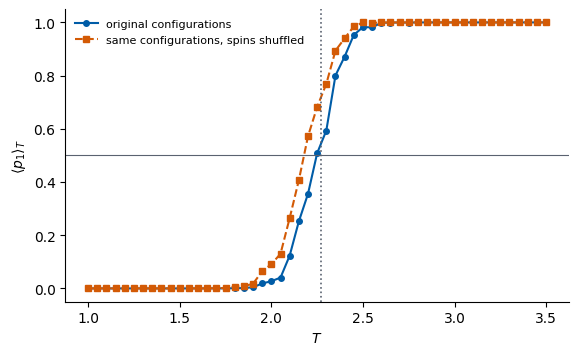

  T     <p_1> original   <p_1> shuffled   <|m|>
1.50      0.000            0.000          0.987
2.00      0.027            0.091          0.915
2.20      0.356            0.572          0.775
2.30      0.594            0.769          0.658
2.40      0.871            0.940          0.488
2.60      0.999            1.000          0.254
3.00      1.000            1.000          0.133


In [10]:
shuffled = configs.reshape(*configs.shape[:2], -1).copy()
for t in range(shuffled.shape[0]):
    for k in range(shuffled.shape[1]):
        rng.shuffle(shuffled[t, k])                                   # random permutation of the sites, same m
shuffled = shuffled.reshape(configs.shape)
p1_shuf = predict(model, shuffled)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(temperatures, p1.mean(1), "o-", color=UJBlue, ms=4, label="original configurations")
ax.plot(temperatures, p1_shuf.mean(1), "s--", color=DSOrange, ms=4, label="same configurations, spins shuffled")
ax.axvline(TC, color=UJGray, ls=":", lw=1.2); ax.axhline(0.5, color=UJGray, lw=0.8)
ax.set_xlabel("$T$"); ax.set_ylabel(r"$\langle p_1\rangle_T$"); ax.legend(frameon=False, fontsize=8)
plt.show()

print("  T     <p_1> original   <p_1> shuffled   <|m|>")
for T in (1.5, 2.0, 2.2, 2.3, 2.4, 2.6, 3.0):
    i = np.argmin(np.abs(temperatures - T))
    print(f"{temperatures[i]:.2f}      {p1[i].mean():.3f}            {p1_shuf[i].mean():.3f}          {absm[i].mean():.3f}")

Compare the two curves (and the printed table). Where they coincide, shuffling did not matter: those configurations are classified by their magnetisation alone.
Where they differ, the network's decision depends on the **arrangement** of the spins, not only on how many point up — for example on the size of clusters,
which is what changes most near $T_c$.

*In the run stored in this notebook:* far from $T_c$ shuffling changes nothing, but around $T_c$ the shuffled configurations are called "disordered" more often.
Without their large clusters they look more like high-temperature noise to the network, at exactly the same $m$.

### 7.3 The learned filters
The first layer applies $32$ different $3\times3$ filters to the spin image. A filter with all weights of the same sign computes a local (smoothed) magnetisation;
a filter with weights of both signs responds to local *differences*, i.e. domain walls — which is what the bond energy $-s_is_j$ measures.

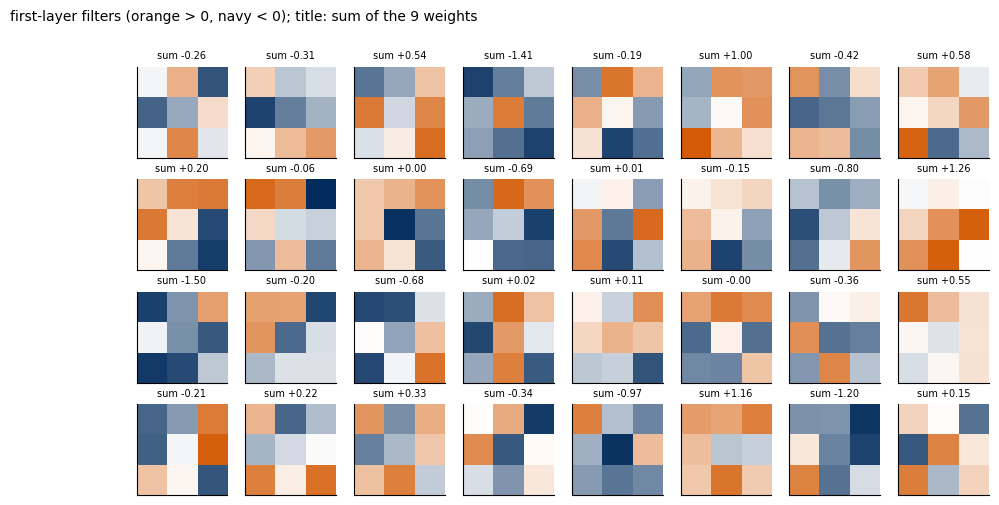

fraction of filters whose 9 weights all have the same sign: 0.00
relative change of the first-layer filters during training, |W - W0| / |W0| = 8.003


In [11]:
W = model.features[0].weight.detach().numpy()[:, 0]                  # (32, 3, 3)
vmax = np.abs(W).max()
fig, axes = plt.subplots(4, 8, figsize=(11, 5.6))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(W[k], cmap=cmap_w, vmin=-vmax, vmax=vmax)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"sum {W[k].sum():+.2f}", fontsize=7)
fig.suptitle("first-layer filters (orange > 0, navy < 0); title: sum of the 9 weights", x=0.01, ha="left", fontsize=10)
plt.show()

same_sign = np.mean([np.all(w > 0) or np.all(w < 0) for w in W])
change = np.linalg.norm(W - W0.numpy()) / np.linalg.norm(W0.numpy())
print(f"fraction of filters whose 9 weights all have the same sign: {same_sign:.2f}")
print(f"relative change of the first-layer filters during training, |W - W0| / |W0| = {change:.3f}")

The printed relative change shows that training moved the filters far from their random initial values, so they are learned, not leftovers. Yet
in the run stored here none of them is a plain local average of the spins. Each mixes positive and negative weights, i.e. it responds to local spin *patterns*.
Whatever the network computes is spread over all the layers (the *systems reply* of Lecture 4). Individual filters are hard to read, and any
physical interpretation has to be tested from outside, as in 7.1 and 7.2.

**Take-home message.**
* The network's output is strongly tied to the magnetisation — the order parameter we know from physics — although nobody told it about $m$.
  The shuffle test shows to what extent it also uses spatial structure.
* Even so, finding this out required **us**: we chose $|m|$ as the hypothesis, designed the shuffle test and interpreted the filters. The network itself gave a
  number, $\bar T_c$, not an explanation. This is the point of the Chinese room — and of opening it (*interpretability*).
* Exact understanding came from somewhere else: Onsager's solution (Lecture 4).
<hr/>
## 8. Exercises
1. Move the training windows: $T_{\min}=1.8$, $T_{\max}=2.8$, or asymmetric ones. How does $\bar T_c$ react? When does it become unreliable?
2. Replace the CNN by a fully connected network on the flattened image (as for MNIST). Is it as good? Does the shuffle test give a different answer? (Hint: a fully connected network has no notion of neighbours.)
3. Remove the random global spin flip from the data (Lab 010, Section 5) — i.e. all low-$T$ configurations have $m>0$. Train again and test on flipped configurations $-\boldsymbol s$. What went wrong?
4. Train with **three** classes (low, intermediate, high temperature bins) or regress $T$ directly. What does the network predict near $T_c$?